Name:Aadesh A Raut          
Roll No. :52 CSE(DS)

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import kagglehub
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    log_loss
)

print("Scikit-learn Version:", sklearn.__version__)
print("Libraries imported successfully!")



Scikit-learn Version: 0.24.2
Libraries imported successfully!


In [2]:
%pip install kagglehub

Note: you may need to restart the kernel to use updated packages.


In [3]:

path = kagglehub.dataset_download("arezaei81/heartcsv")

csv_file = None

for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith(".csv"):
            csv_file = os.path.join(root, file)
            break
    if csv_file:
        break

if csv_file is None:
    raise FileNotFoundError("CSV dataset not found!")

df = pd.read_csv(csv_file)

print("Dataset downloaded successfully!")
print("Dataset Shape:", df.shape)
display(df.head())


Dataset downloaded successfully!
Dataset Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [12]:
csv_file = next(
    os.path.join(root, file)
    for root, dirs, files in os.walk(path)
    for file in files
    if file.endswith(".csv")
)

df = pd.read_csv(csv_file)

print("Dataset Shape:", df.shape)
display(df.head())
df.info()

Dataset Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [4]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [5]:

df = df.drop_duplicates().copy()

# Separate input features and target
X = df.drop("target", axis=1)
y = df["target"]

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Feature scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Data preprocessing completed!")
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Data preprocessing completed!
Training Data: (241, 13)
Testing Data: (61, 13)


In [6]:

gd_model = SGDClassifier(
    loss="log",
    learning_rate="constant",
    eta0=0.01,
    max_iter=1000,
    random_state=42,
    tol=1e-3
)

gd_model.fit(X_train, y_train)

# Generate predictions
y_pred = gd_model.predict(X_test)

print("Gradient Descent Model Trained Successfully!")


Gradient Descent Model Trained Successfully!


In [7]:

print("Model Evaluation Results")
print("-" * 35)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))


Model Evaluation Results
-----------------------------------
Accuracy: 0.7869
Precision: 0.7632
Recall: 0.8788
F1 Score: 0.8169

Classification Report:

              precision    recall  f1-score   support

           0       0.83      0.68      0.75        28
           1       0.76      0.88      0.82        33

    accuracy                           0.79        61
   macro avg       0.79      0.78      0.78        61
weighted avg       0.79      0.79      0.78        61



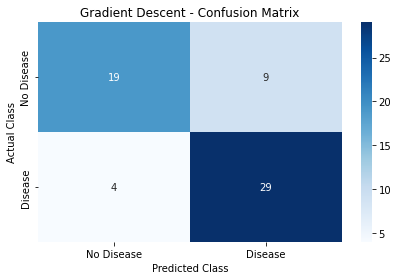

In [8]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.title("Gradient Descent - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


,Actual,Predicted
0,0,0
1,0,0
2,0,0
3,0,1
4,0,1
5,0,0
6,1,1
7,0,0
8,1,1
9,0,1


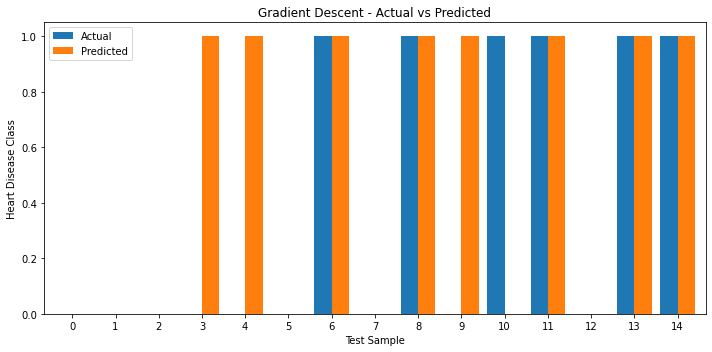

In [9]:

results = pd.DataFrame({
    "Actual": np.asarray(y_test),
    "Predicted": y_pred
}).reset_index(drop=True)

display(results.head(15))

results.head(15).plot(
    kind="bar",
    figsize=(10, 5),
    width=0.8
)

plt.title("Gradient Descent - Actual vs Predicted")
plt.xlabel("Test Sample")
plt.ylabel("Heart Disease Class")
plt.xticks(rotation=0)
plt.legend(["Actual", "Predicted"])
plt.tight_layout()
plt.show()


Log Loss: 0.4326


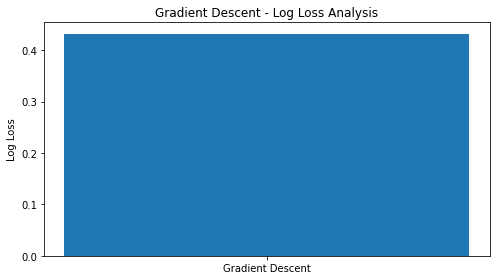

In [10]:

y_prob = gd_model.predict_proba(X_test)

loss = log_loss(
    y_test,
    y_prob,
    labels=gd_model.classes_
)

print("Log Loss:", round(loss, 4))

plt.figure(figsize=(7, 4))
plt.bar(["Gradient Descent"], [loss])

plt.title("Gradient Descent - Log Loss Analysis")
plt.ylabel("Log Loss")
plt.tight_layout()
plt.show()


In [11]:

print("=" * 45)
print("GRADIENT DESCENT ANALYSIS COMPLETED")
print("=" * 45)

print(f"Accuracy  : {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(f"Precision : {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Log Loss  : {loss:.4f}")

print("\nDataset Records:", len(df))
print("Training Samples:", len(y_train))
print("Testing Samples:", len(y_test))

print("\nProject executed successfully!")


GRADIENT DESCENT ANALYSIS COMPLETED
Accuracy  : 78.69%
Precision : 0.7632
Recall    : 0.8788
F1 Score  : 0.8169
Log Loss  : 0.4326

Dataset Records: 302
Training Samples: 241
Testing Samples: 61

Project executed successfully!
